# ERα–SRC2 ligand MD: analysis, figures and end-point energies

This notebook reads the finished production runs from Google Drive: 9 systems × 3 independent replicas × 100 ns.
It computes stability and interaction measures and MM/GBSA end-point energies, and draws the publication figures.
Each stage saves its output to Drive (`eralpha-antidepressant-md/analysis/`) and skips work that is already done, so the notebook
can be rerun after a disconnect without losing anything.

| Output | What it shows |
|---|---|
| `Fig_MD_rmsd` | ligand RMSD per replica (mean ± SEM band), symmetry-corrected |
| `Fig_MD_interactions` | pose retention, ΔΔE versus estradiol at ε_in = 1, 2, 4 and PB, interaction occupancy |
| `FigS*` | receptor and helix-12 RMSD, RMSF, SRC2 coactivator, ligand distances, convergence, decomposition, sensitivity, run QC |
| `tables/main_table.csv` | the summary table: end-point energies, retention and anchor occupancy per system |

**Statistics.** The unit of replication is the replica (*n* = 3). Frames inside one simulation are correlated, so they
are averaged per replica first. Uncertainties are the SEM of the three replica means, with t-based 95 % confidence
intervals.

## 0 · Setup
Parameters: change `KEYS` to restrict the run to some systems (e.g. `['estradiol_rep1']` for a pilot).

In [ ]:
DRIVE_ROOT = "/content/drive/MyDrive/shokouh-md"   # written by the production run
REPO_URL   = "https://github.com/masoudrezaei082-afk/shokouh-md.git"
REPO       = "/content/md-workflow"
ENV        = "/content/mamba/envs/tools"            # pinned GROMACS 2026.3 / AmberTools 26 / MDAnalysis env
KEYS       = None                                    # None = all 27 replicas
NPROC      = 2                                       # MPI ranks for gmx_MMPBSA (free Colab CPU: 2 vCPU)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import os
assert os.path.isdir(f"{DRIVE_ROOT}/runs"), "shokouh-md/runs not found on Drive"
if not os.path.isdir(REPO):
    !git clone -q --depth 1 {REPO_URL} {REPO}
else:
    !git -C {REPO} pull -q

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


The analysis runs in a pinned environment (the same lock file as the simulation container), created with
micromamba. It takes about 10 minutes the first time and is skipped when it already exists. The notebook kernel only
orchestrates the work and displays the results; every computation runs in this environment.

In [ ]:
import subprocess, os, json, time
if not os.path.exists(f"{ENV}/bin/gmx_MMPBSA"):
    !curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/2.3.2 | tar -xj -C /content bin/micromamba
    !MAMBA_ROOT_PREFIX=/content/mamba /content/bin/micromamba create -q -y -p {ENV} --file {REPO}/docker/tools-env.lock.txt
    !{ENV}/bin/pip install -q "gmx_MMPBSA==1.7.0" "spyrmsd==0.9.0" pyarrow openpyxl
RUN_ENV = dict(os.environ, MPLBACKEND="Agg", AMBERHOME=ENV, PATH=f"{ENV}/bin:" + os.environ["PATH"],
               PYTHONPATH=f"{REPO}/analysis", MDANA_DRIVE=DRIVE_ROOT)

def envpy(args, background=None, timeout=None):
    """Run `python <args>` in the analysis env; background=<log path> detaches it (survives this cell)."""
    if background:
        cmd = f"nohup {ENV}/bin/python {args} > {background} 2>&1 &"
        subprocess.Popen(cmd, shell=True, env=RUN_ENV, start_new_session=True)
        return f"started; log: {background}"
    r = subprocess.run(f"{ENV}/bin/python {args}", shell=True, env=RUN_ENV, capture_output=True, text=True,
                       timeout=timeout)
    if r.returncode:
        raise RuntimeError(r.stderr[-3000:])
    return r.stdout

print(envpy("-m mdana.stats"))   # unit test of the statistics on hand-checked toy data
keys = " ".join(KEYS) if KEYS else ""
ANALYSIS = f"{DRIVE_ROOT}/analysis"

stats self-test passed



## 1–3 · Trajectories and structural measures

For each replica:

1. **Join.** The 100-ns trajectory was written in parts. A part interrupted by a crash overlaps the next one; the
   overlap is dropped. The joined trajectory must hold 10,001 frames (one every 10 ps from 0 to 100 ns).
2. **Clean up the periodic box.** The simulation box repeats in every direction, so a molecule can appear split, or
   sit next to a copy of the receptor rather than the receptor itself. Every molecule is made whole, and the SRC2
   peptide and the ligand are moved next to the receptor. Each frame is then superimposed on the binding-pocket
   Cα atoms of the starting structure.
3. **Measure.** Each measure is described in plain language for the reader:
   * **Ligand RMSD:** how far, on average, the ligand's heavy atoms have moved from the starting (docked or
     crystal) pose, after the pocket is superimposed. It is *symmetry-corrected*, so swapping two equivalent atoms
     (for example a flipped ring) does not count as movement.
   * **Pose retention:** the share of the 20–100 ns frames in which that RMSD stays below 2 Å, i.e. the ligand is
     still in essentially its starting pose. Higher means more stable.
   * **Out of contact:** frames where no ligand atom is within 4 Å of the protein, meaning the ligand has left the
     pocket.
   * **Receptor backbone RMSD, Cα RMSF, helix-12 RMSD:** overall structural drift, residue flexibility, and the
     position of helix 12, which controls coactivator binding.
   * **SRC2 RMSD and charge clamp:** whether the coactivator peptide stays bound in its groove. The clamp is
     Lys362 and Glu542 holding the peptide's backbone ends.
   * **Contacts, H-bonds, salt bridges:** the share of frames in which each residue touches, H-bonds or forms an
     ion pair with the ligand. The key anchors are Glu353, Arg394 and His524.

The first 20 ns of production are excluded from every average (equilibration), and are shaded grey in the figures.

**What these measures do *not* show.** They describe whether a pose is stable at equilibrium on a 100-ns scale. They
do not give binding kinetics, residence times or off-rates.

This stage runs in the background (about 10 min per replica). Re-run the status cell until all replicas are done.

In [ ]:
print(envpy(f"-m mdana.pipeline structure {'--keys ' + keys if keys else ''}", background="/content/structure.log"))

started; log: /content/structure.log


In [ ]:
p = f"{ANALYSIS}/structure_progress.json"
if os.path.exists(p):
    s = json.load(open(p))
    print(f"done {len(s['done'])}/{s['total']}, current: {s.get('current')}, failed: {[f['id'] for f in s['failed']]}")
!tail -n 3 /content/structure.log

done 27/27, current: None, failed: []


## 4 · MM/GBSA and MM/PBSA end-point energies

MM/GBSA estimates how much more favourable the energy of the complex is than that of the separated receptor and
ligand, using frames from the simulation and an implicit-solvent model. It is an **end-point energy without entropy**,
not a binding free energy or an affinity. It is used here only to *rank* ligands against estradiol (the native
agonist) and a decoy (the negative control).

Settings, each justified in the committed input files `analysis/mmpbsa_gb.in` and `mmpbsa_pb.in`:

* **Frames:** 20–100 ns, one every 0.5 ns, giving 160 frames per replica and 480 per system.
* **GB model:** GB-neck2 (`igb = 8`) with its matching mbondi3 radii.
* **Salt:** 0.15 M, the same as in the explicit-solvent simulations.
* **Interior dielectric ε_in = 1, 2 and 4.** The ranking is reported only where it holds at all three values.
* **PB cross-check:** a Poisson–Boltzmann calculation at ε_in = 2 on every third frame.
* **Per-residue decomposition:** at ε_in = 2 only.

The 96 jobs run one after another in a background process, with ε_in = 2 first. A disconnected runtime resumes at
the next unfinished job.

In [ ]:
print(envpy(f"-m mdana.mmgbsa run --np {NPROC} {'--keys ' + keys if keys else ''}", background="/content/mmgbsa.log"))

started; log: /content/mmgbsa.log


In [ ]:
print(envpy("-m mdana.mmgbsa status"))
!grep -E "ΔTOTAL|FAILED" /content/mmgbsa.log | tail -n 5

{
 "started": "2026-10-07 20:28:08",
 "total": 96,
 "done": 0,
 "failed": [],
 "current": "estradiol_rep1/gb_eps2",
 "pid": 72568,
 "wall_s": {},
 "updated": "2026-10-07 20:28:08"
}



## 5 · Statistics and tables

* **System values:** per-replica means are combined into a system mean, its SEM and a t-based 95 % CI (n = 3).
* **ΔΔE versus estradiol:** the difference of means with Welch's 95 % CI.
* **Stating an ordering:** a ligand is called more or less favourable than estradiol only if the CI excludes zero
  at *every* ε_in and in PB. Otherwise the result is reported as "not resolved".
* **Convergence:**
  * Block averaging (Flyvbjerg–Petersen) within each replica.
  * Running means of ΔE.
  * A comparison of the first and second halves of the run.
* **Ranking agreement:** Spearman's ρ between the rankings at different ε_in, and between GB and PB.
* **Old versus new:** a comparison with the original single-run results.
* **Clustering:** ligand poses are clustered (GROMOS, 2 Å). The centroid complexes are saved as PDB files for the
  structure figures.

In [ ]:
print(envpy("-c 'from mdana import aggregate as A; t, s = A.run(); import json; print(json.dumps(s, indent=1, default=float))'"))
import pandas as pd
pd.set_option("display.width", 200, "display.max_columns", 30)
pd.read_csv(f"{ANALYSIS}/tables/main_table.csv")

{
 "n_replicas_with_metrics": 27,
 "n_energy_jobs": 96,
 "rank_agreement": {
  "gb1_vs_gb2": {
   "rho": 0.929,
   "p": 0.0009,
   "n_systems": 8
  },
  "gb2_vs_gb4": {
   "rho": 0.952,
   "p": 0.0003,
   "n_systems": 8
  },
  "gb1_vs_gb4": {
   "rho": 0.881,
   "p": 0.0039,
   "n_systems": 8
  },
  "gb2_vs_pb2": {
   "rho": 0.5,
   "p": 0.207,
   "n_systems": 8
  }
 },
 "ordering_vs_estradiol": {
  "decoy": "not resolved",
  "hnk": "higher",
  "imipramine": "not resolved",
  "pape1": "not resolved",
  "r_fluoxetine": "not resolved",
  "s_fluoxetine": "not resolved",
  "s_ketamine": "higher"
 },
 "thresholds": {
  "retention_A": 2.0,
  "clamp_A": 4.0,
  "out_of_contact_A": 4.0,
  "cluster_A": 2.0,
  "equilibration_ns": 20.0
 }
}



,System,ΔE_GB ε1,ΔE_GB ε2,ΔE_GB ε4,ΔE_PB ε2,ΔΔE_GB ε2 vs E2 [95% CI],Pose retention (%),H-bond Glu353 (%),H-bond Arg394 (%),H-bond His524 (%)
0,Estradiol,-37.9 ± 0.4,-42.2 ± 0.2,-44.4 ± 0.2,-9.9 ± 0.3,ref.,100 ± 0,20,0,77
1,PaPE-1,-34.1 ± 0.2,-38.9 ± 0.2,-41.3 ± 0.3,-9.5 ± 0.8,"+3.3 [+2.5, +4.1]",66 ± 14,58,0,25
2,Imipramine,-33.3 ± 0.5,-40.6 ± 0.2,-44.3 ± 0.1,-9.0 ± 1.5,"+1.6 [+0.7, +2.5]",6 ± 6,0,0,1
3,S-Ketamine,-21.4 ± 0.6,-29.2 ± 0.4,-33.1 ± 0.3,-2.5 ± 1.3,"+13.0 [+11.5, +14.5]",47 ± 26,0,0,4
4,"(2R,6R)-HNK",-19.3 ± 2.1,-26.8 ± 1.6,-30.5 ± 1.4,-2.9 ± 1.5,"+15.4 [+8.7, +22.2]",0 ± 0,0,0,29
5,R-Fluoxetine,-33.7 ± 0.3,-40.8 ± 0.3,-44.3 ± 0.3,-12.5 ± 0.2,"+1.4 [+0.4, +2.5]",93 ± 4,84,0,0
6,S-Fluoxetine,-35.4 ± 0.7,-41.4 ± 0.4,-44.4 ± 0.3,-11.5 ± 1.2,"+0.8 [-0.7, +2.3]",38 ± 10,76,0,0
7,Decoy,-38.7 ± 2.7,-49.3 ± 2.9,-54.6 ± 3.1,-8.0 ± 1.7,"-7.1 [-19.4, +5.2]",3 ± 3,0,0,0
8,Apo,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0


In [ ]:
for name in ("ddE_vs_estradiol", "structure_per_system", "old_vs_new", "convergence"):
    f = f"{ANALYSIS}/tables/{name}.csv"
    if os.path.exists(f):
        print(name); display(pd.read_csv(f).round(3))

ddE_vs_estradiol


,sys,label,method,eps,diff,se,df,lo,hi,p,ordering_vs_estradiol
0,pape1,PaPE-1,gb,2,3.307,0.282,3.585,2.486,4.128,0.001,not resolved
1,pape1,PaPE-1,pb,2,0.410,0.824,2.508,-2.530,3.350,0.659,not resolved
2,pape1,PaPE-1,gb,4,3.057,0.333,3.326,2.053,4.061,0.002,not resolved
3,pape1,PaPE-1,gb,1,3.803,0.430,3.446,2.529,5.077,0.002,not resolved
4,imipramine,Imipramine,pb,2,0.827,1.481,2.147,-5.145,6.798,0.629,not resolved
5,imipramine,Imipramine,gb,1,4.580,0.654,3.463,2.648,6.512,0.004,not resolved
6,imipramine,Imipramine,gb,2,1.593,0.298,3.431,0.709,2.478,0.009,not resolved
7,imipramine,Imipramine,gb,4,0.100,0.214,3.609,-0.522,0.722,0.668,not resolved
8,s_ketamine,S-Ketamine,gb,2,13.000,0.440,2.614,11.480,14.530,0.000,higher
9,s_ketamine,S-Ketamine,gb,1,16.420,0.658,3.443,14.470,18.370,0.000,higher


structure_per_system


,sys,label,lig_rmsd_mean,lig_rmsd_sem,lig_rmsd_lo,lig_rmsd_hi,retention_mean,retention_sem,retention_lo,retention_hi,lig_pocket_dist_mean,lig_pocket_dist_sem,lig_pocket_dist_lo,lig_pocket_dist_hi,out_of_contact_mean,...,clamp_k362_lo,clamp_k362_hi,clamp_e542_mean,clamp_e542_sem,clamp_e542_lo,clamp_e542_hi,clamp_formed_mean,clamp_formed_sem,clamp_formed_lo,clamp_formed_hi,lig_rmsd_t0_mean,lig_rmsd_t0_sem,lig_rmsd_t0_lo,lig_rmsd_t0_hi,n
0,estradiol,Estradiol,0.797,0.057,0.550,1.043,0.999,0.001,0.996,1.003,1.664,0.033,1.522,1.806,0.0,...,2.797,3.724,5.635,0.618,2.976,8.294,0.126,0.081,-0.223,0.475,0.662,0.057,0.415,0.908,3
1,pape1,PaPE-1,1.796,0.120,1.280,2.312,0.659,0.139,0.059,1.259,2.277,0.067,1.990,2.564,0.0,...,2.621,3.447,4.990,0.654,2.177,7.802,0.384,0.152,-0.271,1.039,1.337,0.444,-0.574,3.248,3
2,imipramine,Imipramine,4.167,0.644,1.396,6.938,0.057,0.057,-0.188,0.301,2.896,0.619,0.232,5.560,0.0,...,2.460,4.108,6.054,0.172,5.313,6.795,0.079,0.026,-0.034,0.192,2.280,1.022,-2.115,6.676,3
3,s_ketamine,S-Ketamine,2.490,0.693,-0.491,5.471,0.475,0.256,-0.629,1.578,1.978,0.036,1.823,2.134,0.0,...,2.828,3.911,5.754,0.804,2.293,9.214,0.161,0.066,-0.121,0.443,2.307,0.254,1.214,3.399,3
4,hnk,"(2R,6R)-HNK",4.351,0.448,2.423,6.280,0.000,0.000,0.000,0.000,2.646,0.625,-0.043,5.334,0.0,...,2.267,4.230,5.833,0.817,2.317,9.349,0.154,0.058,-0.095,0.402,2.922,0.700,-0.088,5.933,3
5,r_fluoxetine,R-Fluoxetine,1.412,0.109,0.942,1.883,0.932,0.039,0.764,1.101,0.871,0.132,0.302,1.439,0.0,...,2.503,3.942,4.944,0.628,2.244,7.644,0.292,0.194,-0.540,1.125,1.926,0.219,0.986,2.867,3
6,s_fluoxetine,S-Fluoxetine,2.785,0.674,-0.117,5.687,0.382,0.100,-0.047,0.812,2.289,0.715,-0.788,5.365,0.0,...,-1.043,9.772,6.271,0.744,3.069,9.473,0.120,0.061,-0.142,0.382,1.921,0.135,1.341,2.501,3
7,decoy,Decoy,4.077,1.025,-0.332,8.486,0.030,0.029,-0.093,0.154,3.019,0.889,-0.806,6.845,0.0,...,3.142,3.605,7.922,1.308,2.295,13.550,0.034,0.031,-0.099,0.167,2.250,0.089,1.867,2.633,3
8,apo,Apo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.379,4.726,7.376,1.150,2.430,12.320,0.025,0.014,-0.034,0.084,NaN,NaN,NaN,NaN,3


old_vs_new


,sys,label,old_gb,old_pb,old_frames,new_gb_eps2_mean,new_gb_eps2_sem,new_pb_eps2_mean,new_pb_eps2_sem
0,estradiol,Estradiol,-43.59,-30.25,161,-42.21,0.162,-9.870,0.279
1,pape1,PaPE-1,-40.55,-29.58,161,-38.90,0.231,-9.460,0.776
2,imipramine,Imipramine,-42.10,-30.79,161,-40.61,0.250,-9.043,1.454
3,s_ketamine,S-Ketamine,-32.65,-19.51,161,-29.20,0.409,-2.483,1.325
4,hnk,"(2R,6R)-HNK",-23.90,-14.81,161,-26.76,1.591,-2.850,1.547
5,r_fluoxetine,R-Fluoxetine,-37.98,-25.75,161,-40.76,0.289,-12.530,0.208


convergence


,sys,rep,quantity,n,mean,naive_sem,block_sem,plateau,first_half,second_half
0,estradiol,3,lig_rmsd,8001,0.700,0.002,0.020,True,0.716,0.683
1,estradiol,1,lig_rmsd,8001,0.898,0.003,0.053,True,0.798,0.998
2,estradiol,1,dE_gb_eps2,160,-41.940,0.178,0.187,True,-42.350,-41.540
3,estradiol,2,dE_gb_eps2,160,-42.500,0.178,0.365,True,-42.330,-42.670
4,estradiol,3,dE_gb_eps2,160,-42.180,0.179,0.401,True,-41.580,-42.780
5,estradiol,2,lig_rmsd,8001,0.793,0.003,0.035,True,0.825,0.761
6,pape1,3,lig_rmsd,8001,1.668,0.005,0.089,True,1.785,1.551
7,pape1,2,lig_rmsd,8001,2.036,0.003,0.050,True,1.976,2.095
8,pape1,1,lig_rmsd,8001,1.684,0.003,0.068,True,1.538,1.830
9,pape1,3,dE_gb_eps2,160,-38.880,0.180,0.278,True,-38.750,-39.000


## 6 · Figures

All figures share one style:
* Liberation Sans, metrically identical to Arial, at 7 pt.
* Springer Nature column widths.
* One colour-blind-safe colour per system, the same in every figure.
* Each figure is saved as a PDF with embedded fonts, an SVG and a 600-dpi PNG, to Drive `analysis/figures/`.

**Main figures** (replace Fig. 6 and Tables 1–2):
* `Fig_MD_rmsd`: ligand RMSD for each replica, with the mean ± SEM;
* `Fig_MD_interactions`: a, pose retention; b, ΔΔE versus estradiol at each ε_in and in PB; c, residue contact and H-bond occupancy.

**SI figures:**
* S1, receptor and helix-12 RMSD;
* S2, RMSF;
* S3, SRC2 and the charge clamp;
* S4, ligand position;
* S5, convergence;
* S6, per-residue decomposition;
* S7, ε_in and GB/PB sensitivity;
* S8, thermodynamic quality control.


Fig_MD_rmsd


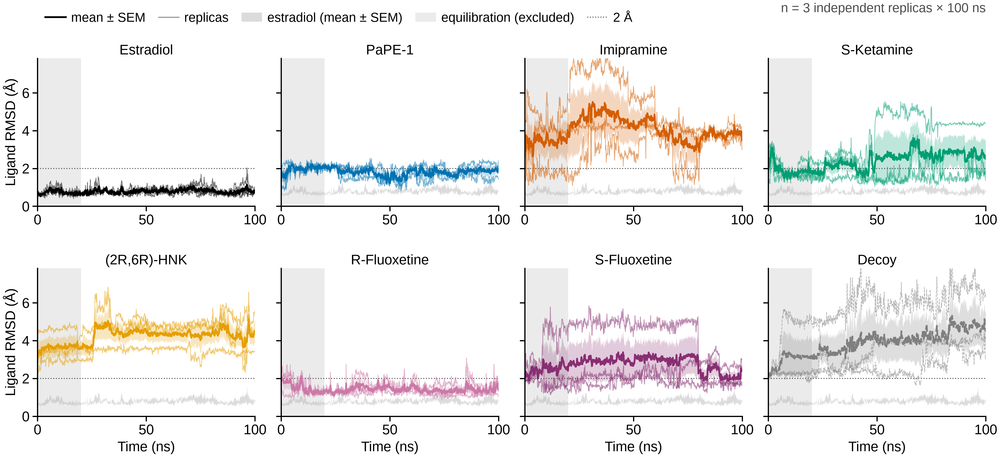

Fig_MD_interactions


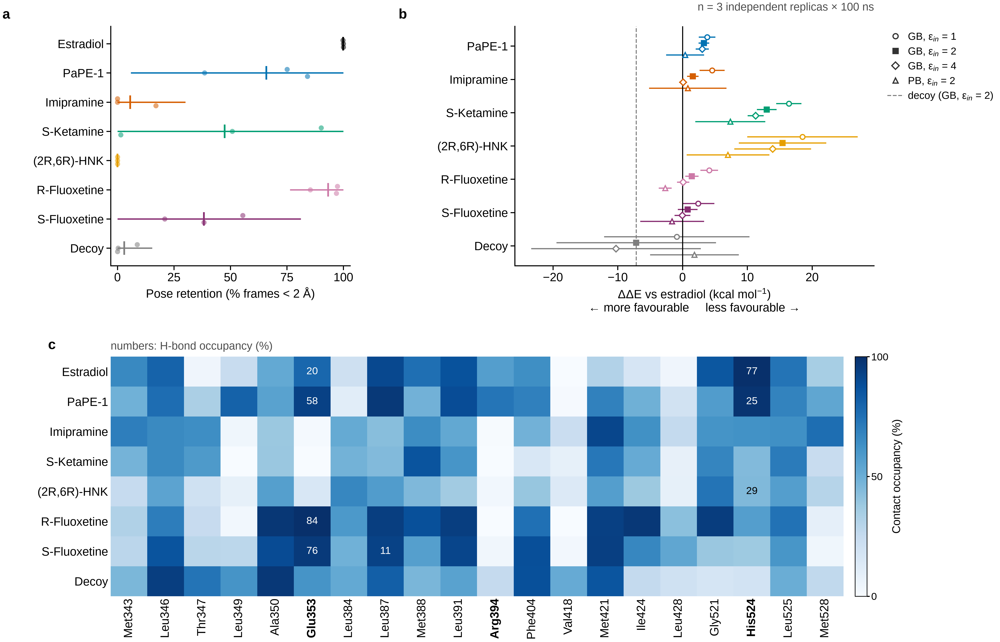

FigS1a_receptor_rmsd


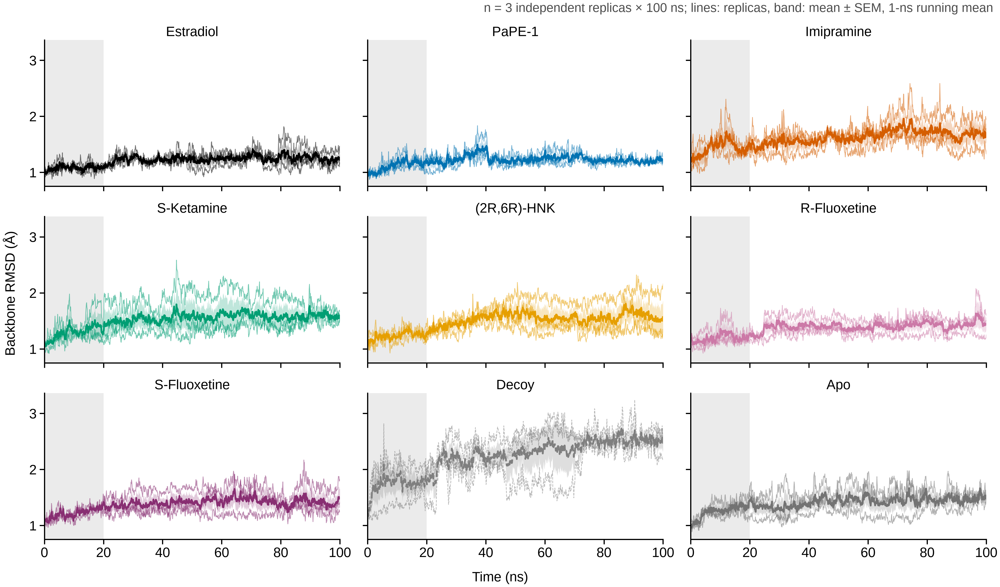

FigS1b_h12_rmsd


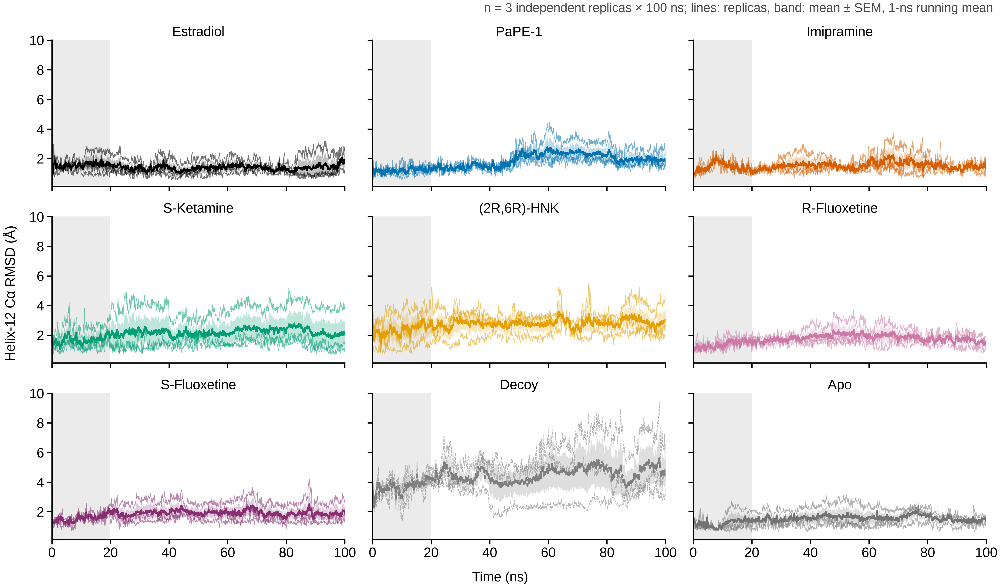

FigS2_rmsf


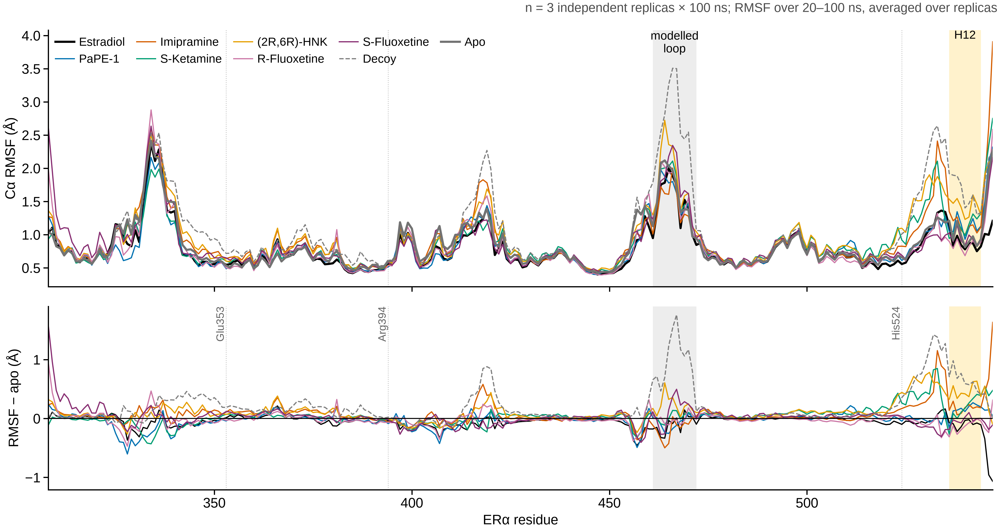

FigS3_coactivator


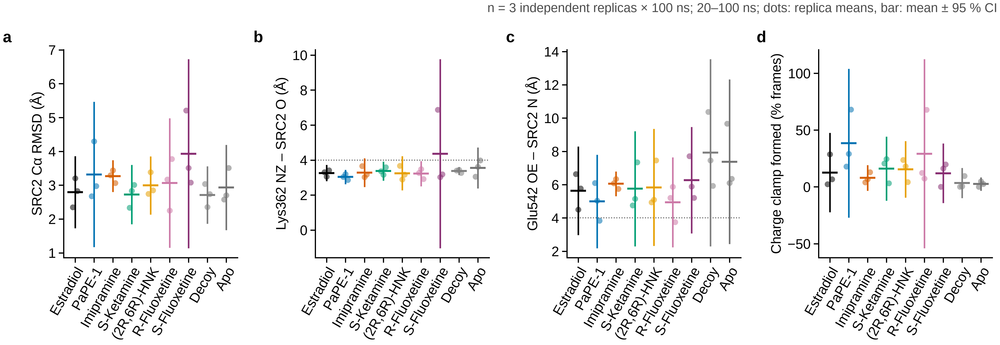

FigS4a_ligand_centroid


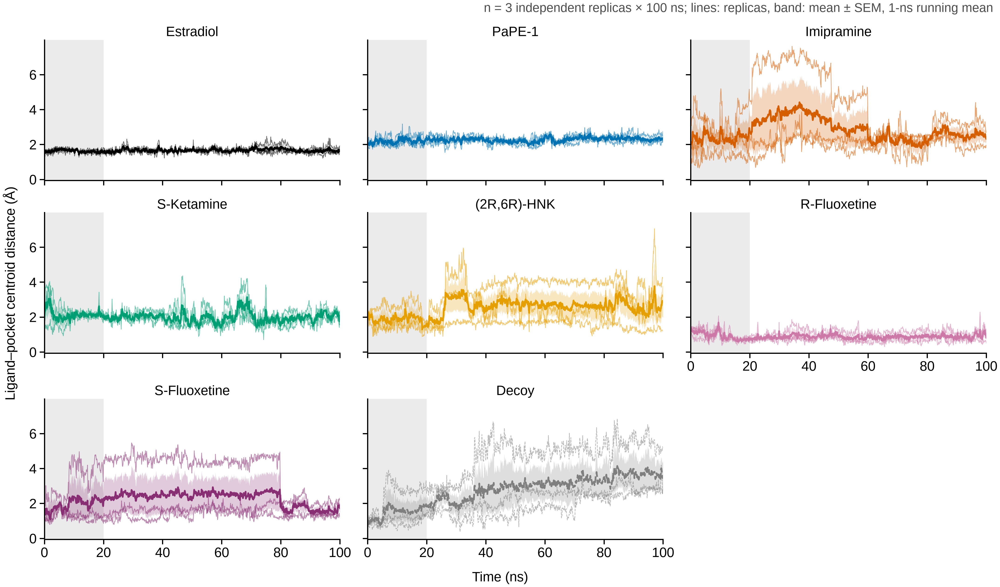

FigS4b_ligand_mindist


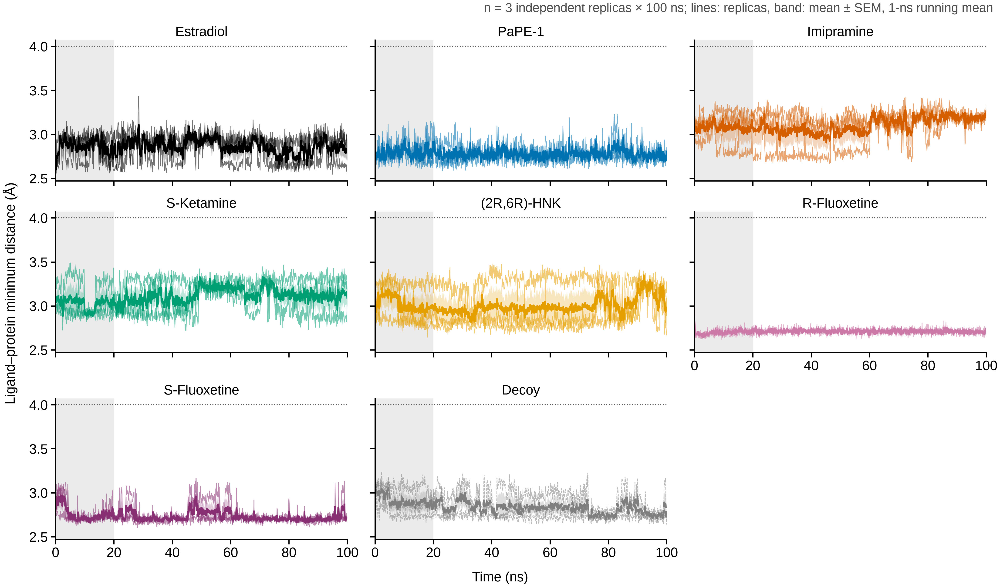

FigS5_convergence


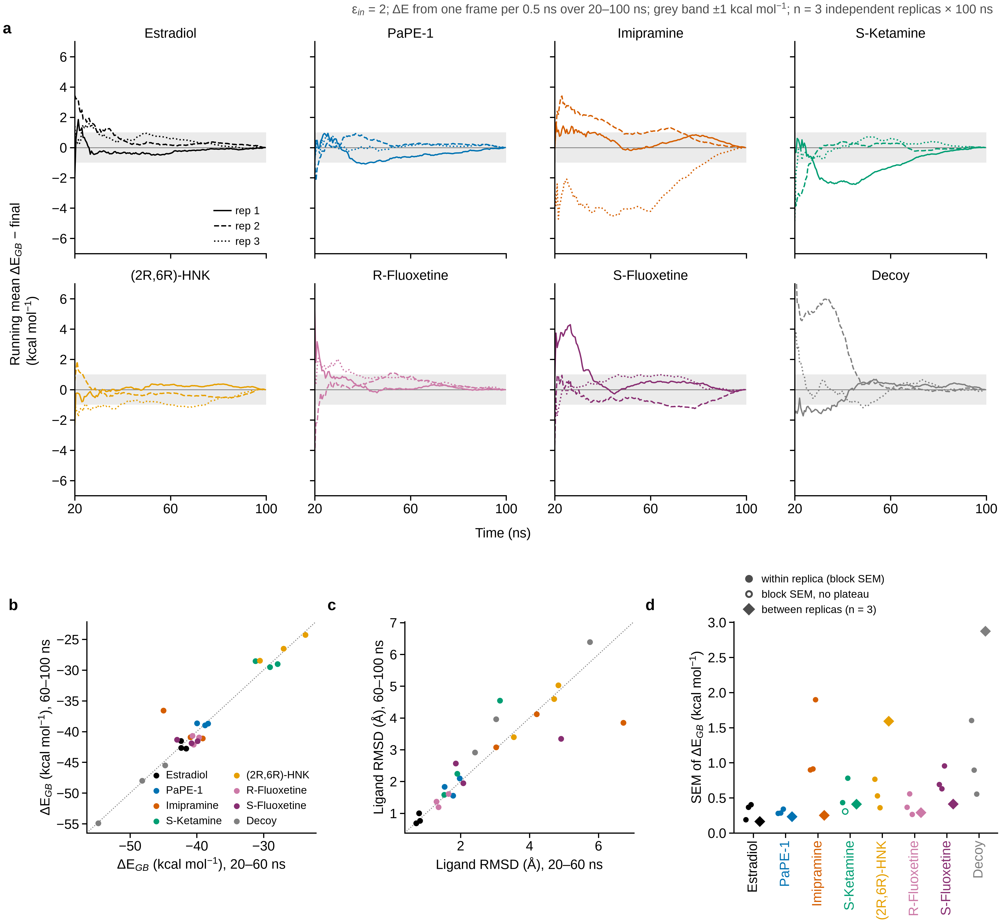

FigS6_decomposition


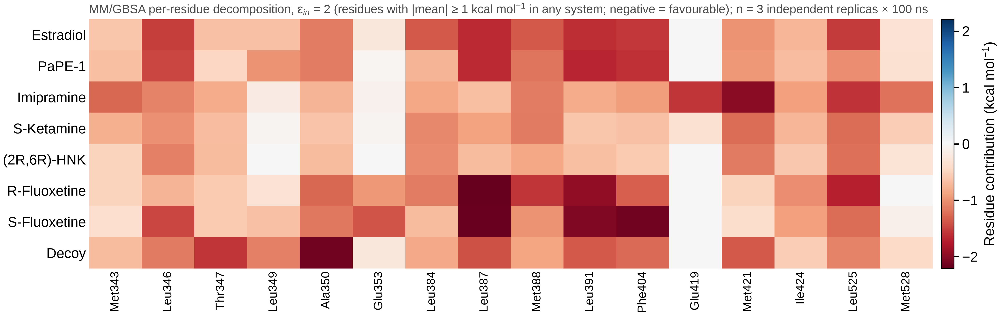

FigS7_sensitivity


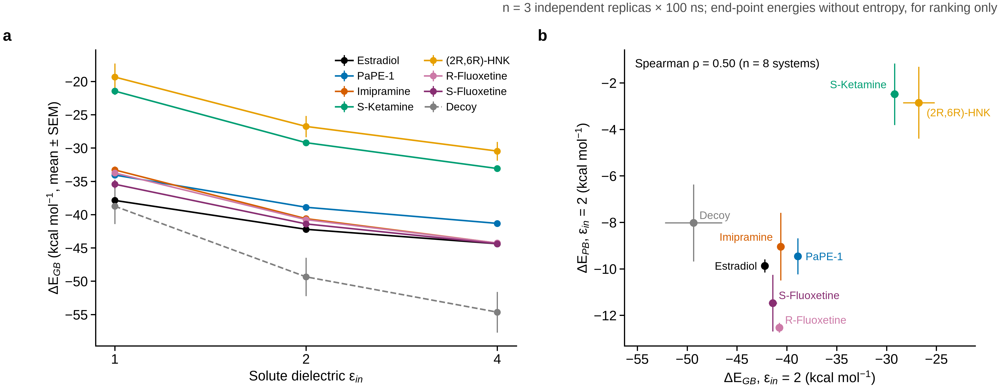

FigS8_qc


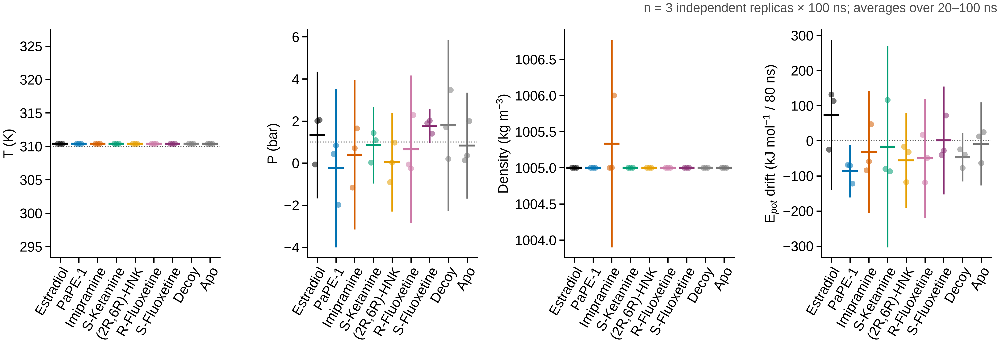

In [ ]:
print(envpy("-c 'from mdana import figures as F; F.all_figures()'"))
from IPython.display import Image, display
import glob
for f in ["Fig_MD_rmsd", "Fig_MD_interactions"] + sorted(os.path.basename(p)[:-4] for p in glob.glob(f"{ANALYSIS}/figures/FigS*.png")):
    print(f); display(Image(f"{ANALYSIS}/figures/{f}.png", width=900))

In [ ]:
!for f in {ANALYSIS}/figures/Fig_MD_*.pdf; do {ENV}/bin/pdffonts $f; done

/bin/bash: line 1: /content/mamba/envs/tools/bin/pdffonts: No such file or directory
/bin/bash: line 1: /content/mamba/envs/tools/bin/pdffonts: No such file or directory


## 7 · Interpretation guide

The results are interpreted with these rules:

* A difference is described as a difference only when its 95 % CI excludes zero at every ε_in. Otherwise the text
  says "comparable within replica spread".
* MM/GBSA values are called *end-point energies* and are used only for ranking, never as affinities.
* Stability statements are limited to "the docked pose was retained (or not) over 100 ns in *k* of 3 replicas". They
  never claim kinetics or residence time.